In [40]:
import io
import pandas as pd

csv_data = """booking_id,customer_name,age,booking_amount,booking_date
1001,Aarav Sharma,28,25000,2026-10-01
1002,Priya Nair,-5,999999,15/10/2026
1003,,34,,2026-13-45
1004,Rohan Verma,twenty-nine,32000,2026-11-02
1005,Ananya Rao,41,18500,2026-11-05
1006,Vikram Singh,150,-12000,2026-11-06
1007,Neha Gupta,26,27500,2026-11-07
1008,Siddharth Joshi,,41000,08-11-2026
1009,Meera Krishnan,31,abc,2026-11-09
1010,Kabir Mehta,-12,19000,2026/11/10
1011,Anjali Deshmukh,29,,2026-11-11
1012,,45,52000,2026-11-12
1013,Arjun Reddy,22,-4500,2026-11-13
1014,Pooja Kulkarni,thirty-five,28900,32/11/2026
1015,Karan Malhotra,38,NULL,2026-11-15
1016,Divya Menon,27,31000,2026-11-16
1017,Harsh Vardhan,0,46000,2026-11-17
1018,Sneha Iyer,,15500,18-11-2026
1019,Nikhil Tiwari,33,NaN,2026-11-19
1020,Ritu Choudhary,205,22400,2026-11-20
1021,,24,-800,2026-11-21
1022,Aditya Bansal,36,64000,2026/11/22
1023,Kavita Dubey,forty,39500,2026-11-23
1024,Manish Agarwal,29,,2026-11-24
1025,Swati Bhatia,-8,21000,2026-14-10
1026,Tarun Gill,47,888888,2026-11-26
1027,Nandini Hegde,30,17800,27/11/2026
1028,,32,49200,2026-11-28
1029,Deepak Yadav,19,-3200,2026-11-29
1030,Shruti Sawant,twenty-four,35600,2026-11-30
1031,Pranav Joshi,42,NaN,2026-12-01
1032,Pallavi Kaul,25,29400,2026-12-02
1033,Gaurav Kapoor,140,12500,03-12-2026
1034,Ishita Sen,,NULL,2026-12-04
1035,Varun Chawla,37,-1500,2026/12/05
1036,,29,43800,2026-12-06
1037,Komal Rathore,forty-three,error,2026-12-07
1038,Suresh Babu,-3,26700,2026-12-08
1039,Alisha Mirza,31,,2026-12-09
1040,Mayank Saxena,23,58900,2026-15-01
1041,Tanvi Oberoi,185,19800,11/12/2026
1042,Rajeshwari Pillai,35,-9500,2026-12-12
1043,,28,33200,2026-12-13
1044,Yashwant Rao,thirty,NaN,2026-12-14
1045,Simran Kaur,46,71500,2026-12-15
1046,Akshay Kulkarni,-1,24300,2026/12/16
1047,Bhavana Shetty,32,,2026-12-17
1048,Dinesh Prajapati,51,16400,31/02/2026
1049,Meenakshi Nair,27,-600,2026-12-19
1050,Prateek Solanki,twenty-seven,47900,2026-12-20"""

df = pd.read_csv(io.StringIO(csv_data))
print("Shape:", df.shape)
df.head(10)

Shape: (50, 5)


,booking_id,customer_name,age,booking_amount,booking_date
0,1001,Aarav Sharma,28,25000,2026-10-01
1,1002,Priya Nair,-5,999999,15/10/2026
2,1003,NaN,34,NaN,2026-13-45
3,1004,Rohan Verma,twenty-nine,32000,2026-11-02
4,1005,Ananya Rao,41,18500,2026-11-05
5,1006,Vikram Singh,150,-12000,2026-11-06
6,1007,Neha Gupta,26,27500,2026-11-07
7,1008,Siddharth Joshi,NaN,41000,08-11-2026
8,1009,Meera Krishnan,31,abc,2026-11-09
9,1010,Kabir Mehta,-12,19000,2026/11/10


In [41]:
print("=== INFO & DTYPES ===")
print(df.info())

print("\n=== MISSING VALUES ===")
print(df.isna().sum())

print("\n=== UNIQUE VALUES IN AGE ===")
print(df["age"].unique())

print("\n=== SAMPLE BOOKING AMOUNT & DATE ===")
print(df[["booking_amount", "booking_date"]].head(15))

=== INFO & DTYPES ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   booking_id      50 non-null     int64 
 1   customer_name   44 non-null     object
 2   age             47 non-null     object
 3   booking_amount  40 non-null     object
 4   booking_date    50 non-null     object
dtypes: int64(1), object(4)
memory usage: 2.1+ KB
None

=== MISSING VALUES ===
booking_id         0
customer_name      6
age                3
booking_amount    10
booking_date       0
dtype: int64

=== UNIQUE VALUES IN AGE ===
['28' '-5' '34' 'twenty-nine' '41' '150' '26' nan '31' '-12' '29' '45'
 '22' 'thirty-five' '38' '27' '0' '33' '205' '24' '36' 'forty' '-8' '47'
 '30' '32' '19' 'twenty-four' '42' '25' '140' '37' 'forty-three' '-3' '23'
 '185' '35' 'thirty' '46' '-1' '51' 'twenty-seven']

=== SAMPLE BOOKING AMOUNT & DATE ===
   booking_amount booking_date
0

In [42]:
# 1. Clean customer_name (fill missing with 'Unknown')
df["customer_name"] = df["customer_name"].fillna("Unknown").str.strip()

# 2. Map word numbers in age to digits
word_to_age = {
    "twenty-four": 24,
    "twenty-seven": 27,
    "twenty-nine": 29,
    "thirty": 30,
    "thirty-five": 35,
    "forty": 40,
    "forty-three": 43,
}

df["age_clean"] = df["age"].replace(word_to_age)
df["age_clean"] = pd.to_numeric(df["age_clean"], errors="coerce")

# Unrealistic ages (< 1 or > 100) ko NaN mark karein
df.loc[(df["age_clean"] < 1) | (df["age_clean"] > 100), "age_clean"] = pd.NA

print(df[["customer_name", "age", "age_clean"]].head(15))
print("\nCleaned age missing count:", df["age_clean"].isna().sum())

      customer_name          age  age_clean
0      Aarav Sharma           28       28.0
1        Priya Nair           -5        NaN
2           Unknown           34       34.0
3       Rohan Verma  twenty-nine       29.0
4        Ananya Rao           41       41.0
5      Vikram Singh          150        NaN
6        Neha Gupta           26       26.0
7   Siddharth Joshi          NaN        NaN
8    Meera Krishnan           31       31.0
9       Kabir Mehta          -12        NaN
10  Anjali Deshmukh           29       29.0
11          Unknown           45       45.0
12      Arjun Reddy           22       22.0
13   Pooja Kulkarni  thirty-five       35.0
14   Karan Malhotra           38       38.0

Cleaned age missing count: 13


In [43]:
# 1. Convert booking_amount to numeric (invalid strings become NaN)
df["amount_clean"] = pd.to_numeric(df["booking_amount"], errors="coerce")

# 2. Negative amounts ko invalid (NaN) mark karein
df.loc[df["amount_clean"] < 0, "amount_clean"] = pd.NA

# 3. High outliers dekhne ke liye summary aur top values check karein
print("Summary stats:\n", df["amount_clean"].describe())
print("\nRows with amount > 100000:\n", df[df["amount_clean"] > 100000][["booking_id", "booking_amount", "amount_clean"]])

# Optional: 100000 se zyada outliers ko NaN set karna ho toh:
# df.loc[df["amount_clean"] > 100000, "amount_clean"] = pd.NA

Summary stats:
 count        31.000000
mean      92231.838710
std      228439.864612
min       12500.000000
25%       21700.000000
50%       31000.000000
75%       46950.000000
max      999999.000000
Name: amount_clean, dtype: float64

Rows with amount > 100000:
     booking_id booking_amount  amount_clean
1         1002         999999      999999.0
25        1026         888888      888888.0


In [44]:
# 1. Parse mixed date formats; invalid calendar dates become NaT
df["date_clean"] = pd.to_datetime(
    df["booking_date"], format="mixed", dayfirst=True, errors="coerce"
)

# 2. Check which rows became NaT (invalid dates)
print("Invalid / NaT count:", df["date_clean"].isna().sum())
print(
    "\nRows with invalid dates:\n",
    df[df["date_clean"].isna()][["booking_id", "booking_date", "date_clean"]],
)

# 3. Preview cleaned dates
print("\nSample cleaned dates:\n", df[["booking_date", "date_clean"]].head(15))

Invalid / NaT count: 3

Rows with invalid dates:
     booking_id booking_date date_clean
2         1003   2026-13-45        NaT
13        1014   32/11/2026        NaT
47        1048   31/02/2026        NaT

Sample cleaned dates:
    booking_date date_clean
0    2026-10-01 2026-10-01
1    15/10/2026 2026-10-15
2    2026-13-45        NaT
3    2026-11-02 2026-11-02
4    2026-11-05 2026-11-05
5    2026-11-06 2026-11-06
6    2026-11-07 2026-11-07
7    08-11-2026 2026-11-08
8    2026-11-09 2026-11-09
9    2026/11/10 2026-11-10
10   2026-11-11 2026-11-11
11   2026-11-12 2026-11-12
12   2026-11-13 2026-11-13
13   32/11/2026        NaT
14   2026-11-15 2026-11-15


In [38]:
# 1. Extreme outliers (> 200000) in amount_clean ko NaN mark karein
df.loc[df["amount_clean"] > 200000, "amount_clean"] = pd.NA

# 2. Missing numeric values ko median se fill karein (skewed/dirty data ke liye median achha rehta hai)
df["age_final"] = df["age_clean"].fillna(df["age_clean"].median()).round().astype(int)
df["amount_final"] = df["amount_clean"].fillna(df["amount_clean"].median()).round(2)

# 3. Clean final table banayein
clean_df = pd.DataFrame({
    "booking_id": df["booking_id"],
    "customer_name": df["customer_name"],
    "age": df["age_final"],
    "booking_amount": df["amount_final"],
    "booking_date": df["date_clean"]
})

print("=== CLEANED DATA SUMMARY ===")
print(clean_df.info())
print("\nMissing values after cleaning:\n", clean_df.isna().sum())
print("\nFirst 12 rows:\n", clean_df.head(12))

# 4. CSV mein save karein
clean_df.to_csv("clean_5cols_50rows.csv", index=False)
print("\nSaved 'clean_5cols_50rows.csv' successfully!")

=== CLEANED DATA SUMMARY ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   booking_id      50 non-null     int64         
 1   customer_name   50 non-null     object        
 2   age             50 non-null     int64         
 3   booking_amount  50 non-null     float64       
 4   booking_date    47 non-null     datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 2.1+ KB
None

Missing values after cleaning:
 booking_id        0
customer_name     0
age               0
booking_amount    0
booking_date      3
dtype: int64

First 12 rows:
     booking_id    customer_name  age  booking_amount booking_date
0         1001     Aarav Sharma   28         25000.0   2026-10-01
1         1002       Priya Nair   31         29400.0   2026-10-15
2         1003          Unknown   34         29400.0      

=== MONTH-WISE SUMMARY ===
     month  total_bookings  total_amount  avg_amount
0  2026-01               1       58900.0    58900.00
1  2026-10               3       75400.0    25133.33
2  2026-11              25      805000.0    32200.00
3  2026-12              18      573700.0    31872.22


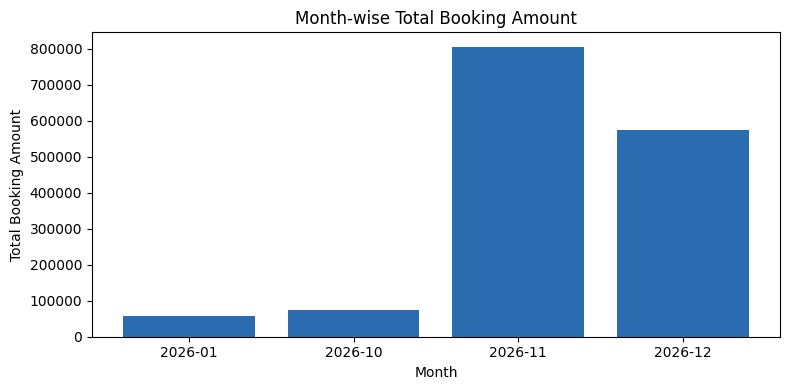

In [45]:
import matplotlib.pyplot as plt

# 1. Month-wise summary (total bookings, total revenue, average amount)
monthly_summary = (
    clean_df.dropna(subset=["booking_date"])
    .assign(month=lambda x: x["booking_date"].dt.to_period("M").astype(str))
    .groupby("month", as_index=False)
    .agg(
        total_bookings=("booking_id", "count"),
        total_amount=("booking_amount", "sum"),
        avg_amount=("booking_amount", "mean"),
    )
    .sort_values("month")
)

monthly_summary["avg_amount"] = monthly_summary["avg_amount"].round(2)
print("=== MONTH-WISE SUMMARY ===")
print(monthly_summary)

# 2. Bar chart visualization
plt.figure(figsize=(8, 4))
plt.bar(
    monthly_summary["month"],
    monthly_summary["total_amount"],
    color="#2b6cb0",
)
plt.title("Month-wise Total Booking Amount")
plt.xlabel("Month")
plt.ylabel("Total Booking Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [46]:
from google.colab import files

# Raw data bhi save karke download kar lein taaki repo mein before & after dono rahein
with open("raw_bookings_dirty.csv", "w") as f:
  f.write(csv_data)

files.download("raw_bookings_dirty.csv")
files.download("clean_5cols_50rows.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>